# 기능 C 냥기사 LoRA + IP-Adapter 비교 (10/30)

12에서 게임 3개 모두 IP-Adapter만 썼고(LoRA 없음), 11에서 냥기사 LoRA를 장수·체크포인트별로 따로 비교했다. 냥기사에 LoRA와 IP-Adapter를 같이 쓴 조합은 실험한 적이 없어, 11의 LoRA 후보 전부를 12와 같은 설정·장면으로 IP-Adapter 켬/끔과 함께 만든다.

| 조건 | 기준 모델 | LoRA | IP-Adapter |
|---|---|---|---|
| 12 결과 그대로 | animagine-xl-4.0 | 없음 | 켬(0.5) / 끔 |
| 새로 만듦 | animagine-xl-4.0-zero | 없음 | 켬 / 끔 |
| 새로 만듦 | 11의 적용 조합 3개(Zero 학습→Zero, Zero 학습→4.0, 4.0 학습→4.0) × 50·100·200·400·800장 = 15개 | 1,600스텝 최종 가중치 | 켬 / 끔 |

- 12와 같은 것 (`outputs/promo_c/c_config.json`을 읽어 그대로 씀)
  - 냥기사 장면 6건(07 R2 Qwen 장면 태그), seed 0·1
  - 프롬프트(`NAI_SHORT, safe, 장면, 품질 태그`), 부정 프롬프트(`…, nsfw`), 참조 이미지(`gen_0053_protagonist.png`)
  - IP-Adapter `h94/IP-Adapter` sdxl, 전체 층 강도 0.5(05 결과), Euler Ancestral 28스텝, CFG 5, 1216×832, bf16
- LoRA를 쓸 때만 장면 뒤에 트리거(`nyang_knight_style`, 11 학습 캡션과 같음)를 붙인다. LoRA 강도는 11과 같이 기본값(1.0)이다.
- LoRA 경로: 800장은 06 결과(`models/lora/{zero,v40}_trigger`), 50~400장은 11 결과(`models/lora/sweep/{zero,v40}_trigger_n{장수}`)
- 지표
  - `style_sim`: 12와 같음(냥기사 생성 원본 `lora_gen` 100장, 참조 이미지 제외, 무작위 seed 0과의 CLIP 평균 유사도)
  - `style_sim_orig`: 11과 같은 기준(냥기사 원본 `data/raw/nai/*.png`와의 CLIP 평균 유사도)
  - `scene_sim`, `two_cat_prob`, `exposed_prob`: 12와 같음
- 기록 (`outputs/promo_c_lora/`)
  - `cl_config.json`: 조건 전체, 12 설정, LoRA 경로, 패키지 버전, GPU
  - `cl_records.csv`: 이미지 1장마다 조건·장면·seed·프롬프트·토큰 수·잘림 여부·생성 시간·최대 VRAM·오류
  - `cl_runs.csv`: 기준 모델마다 시작·종료 시각, 모델 로드 시간, 전체 시간, 장수, 최대 VRAM
  - `cl_scored.csv`, `cl_summary.csv`, `cl_scores.png`, `cl_grid_<적용 조합>.png`
- 진행 출력: `[시각 | 경과 | VRAM] 내용`을 한 줄씩 바로 출력한다(모델·LoRA 로드 시작·끝, 몇 번째/전체).
- 실행 순서: 위에서부터 차례로. 다시 실행하면 오류 없이 만든 이미지는 건너뛴다.
- 예상(추정): 새로 만드는 이미지 (1 + 15) × 2 × 12 = 384장 × 12 장당 약 10.3초 ≈ 66분 + 기준 모델 로드 2번. 새로 받는 모델 없음(animagine-xl-4.0-zero는 06·11에서 받음).
- 10/30 수정: 첫 실행에서 4.0 단계(240장, 장당 평균 11.19초, 최대 VRAM 13.0GB)를 마친 뒤 같은 커널에서 Zero 모델을 불러오자, 4.0 모델이 내려가지 않아 VRAM 21.4GB(최대 23.7GB)가 되고 장당 313~2,994초가 걸렸다(14 F0와 같은 문제). 기준 모델마다 별도 프로세스에서 불러와 생성하도록 바꿨다. 그때 만든 Zero 3장은 시간 기록이 맞지 않아 다시 만든다.
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정

In [1]:
import gc
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
C_DIR = ROOT / 'outputs' / 'promo_c'
OUT_DIR = ROOT / 'outputs' / 'promo_c_lora'
OUT_DIR.mkdir(parents=True, exist_ok=True)
REC_CSV = OUT_DIR / 'cl_records.csv'
RUNS_CSV = OUT_DIR / 'cl_runs.csv'
LORA_DIR = ROOT / 'models' / 'lora'

# 12 설정 그대로
C12 = json.loads((C_DIR / 'c_config.json').read_text(encoding='utf-8'))
NAI = C12['games']['nai']
assert '{scene}' in NAI['prompt_example'] and NAI['ipa'] == 0.5 and NAI['ipa_name'] == 'all_layers' and not NAI['compel']
IPA = C12['ip_adapter']
REF = ROOT / Path(C12['refs']['nai'].replace('\\', '/')).relative_to('..')
SCENES = pd.DataFrame([s for s in C12['scenes'] if s['game'] == 'nai']).reset_index(drop=True)
assert len(SCENES) == 6
G = C12['gen']
W, H, STEPS, CFG, SEEDS = G['width'], G['height'], G['steps'], G['cfg'], G['seeds']

# 11과 같은 LoRA·체크포인트
CKPTS = {'v40': 'cagliostrolab/animagine-xl-4.0', 'zero': 'cagliostrolab/animagine-xl-4.0-zero'}
assert C12['model'] == CKPTS['v40']
TRIGGER = 'nyang_knight_style'
SIZES = [50, 100, 200, 400, 800]
APPLY = [('zero', 'zero'), ('v40', 'zero'), ('v40', 'v40')]  # (적용 체크포인트, 학습 체크포인트)
APPLY_NAME = {('zero', 'zero'): 'LoRA(Zero) on Zero', ('v40', 'zero'): 'LoRA(Zero) on 4.0', ('v40', 'v40'): 'LoRA(4.0) on 4.0'}


def lora_path(train_ckpt, size):
    # 1,600스텝 최종 가중치 (800장은 06, 나머지는 11)
    return (LORA_DIR / f'{train_ckpt}_trigger') if size == 800 else (LORA_DIR / 'sweep' / f'{train_ckpt}_trigger_n{size}')


CONDS = [dict(apply=a, train='', size=0, label=f'{a} no LoRA') for a in ['v40', 'zero']]
CONDS += [dict(apply=a, train=t, size=s, label=APPLY_NAME[(a, t)]) for a, t in APPLY for s in SIZES]
miss = [str(lora_path(c['train'], c['size'])) for c in CONDS if c['train'] and
        not (lora_path(c['train'], c['size']) / 'pytorch_lora_weights.safetensors').exists()]
assert not miss, f'LoRA 가중치가 없음: {miss}'
assert REF.exists(), REF


def prompt_of(scene, lora):
    return NAI['prompt_example'].replace('{scene}', f'{scene}, {TRIGGER}' if lora else scene)


def name_of(c, item, seed, ipa):
    lora = f"lora-{c['train']}-n{c['size']}" if c['train'] else 'nolora'
    return f"CL_{c['apply']}__{lora}__{'ipa' if ipa else 'noipa'}__{item}_s{seed}.png"


print('조건', len(CONDS), '개 × 장면', len(SCENES), '× seed', len(SEEDS), '× IP-Adapter 켬/끔')
display(SCENES[['item', 'request', 'scene']])

recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f):
    return recs.get(f, {}).get('error', 'x') == '' and (OUT_DIR / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 멈춤 여부를 바로 알 수 있게 단계마다 시각·단계 시작 후 경과·VRAM(현재/최대)을 함께 출력
def log(msg, t_start=None):
    el = ''
    if t_start is not None:
        m, sec = divmod(int(time.perf_counter() - t_start), 60)
        el = f' | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d}'
    vr = ''
    if torch.cuda.is_available():
        vr = f' | VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")}{el}{vr}] {msg}', flush=True)

조건 17 개 × 장면 6 × seed 2 × IP-Adapter 켬/끔


,item,request,scene
0,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 ...,"summer beach, sunset, waves, palm trees, sandy..."
1,B1,"할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘","moonlit forest, glowing pumpkins, misty path, ..."
2,B6,벚꽃 핀 봄 언덕에서 냥기사 신규 스킨 공개 배너 만들어줘,"spring_hill, cherry_blossom, soft_light, gentl..."
3,B7,"눈 오는 크리스마스 마을 배경으로 냥기사 겨울 업데이트 배너, 12월 20일 업데이트","snowy village, christmas lights, cat knight, w..."
4,B8,"바다 위 배에서 냥기사 해적 의상 20% 할인 배너, 이번 주말까지","ship at sea, black cat knight, stormy ocean, w..."
5,B9,도서관 배경으로 냥기사 스토리 2장 공개 배너,"library, bookshelves, candlelight, parchment, ..."


## 생성 (기준 모델마다 한 번 불러와 LoRA만 바꿈)

In [2]:
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), from_12=dict(nai=NAI, ip_adapter=IPA, ref=str(REF), gen=G),
    scenes=SCENES.to_dict('records'), ckpts=CKPTS, trigger=TRIGGER, lora_weight='1,600 step final (pytorch_lora_weights.safetensors)',
    conds=[dict(c, lora=str(lora_path(c['train'], c['size'])) if c['train'] else '') for c in CONDS],
    reuse='v40 no LoRA = outputs/promo_c (12) nai 이미지 그대로',
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'peft', 'accelerate', 'pillow', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'cl_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')

# 12의 4.0·LoRA 없음 이미지는 그대로 기록에 넣음 (다시 만들지 않음)
c12 = pd.read_csv(C_DIR / 'c_records.csv', keep_default_na=False)
c12 = c12[(c12.game == 'nai') & (c12.error == '')]
assert len(c12) == len(SCENES) * len(SEEDS) * 2, len(c12)
assert all(r.prompt == prompt_of(r.scene, False) for r in c12.itertuples()), '12 프롬프트와 다름'
for r in c12.itertuples():
    ipa = str(r.use_ipa) == 'True'
    f = name_of(CONDS[0], r.item, int(r.seed), ipa)
    if not done(f):
        Image.open(C_DIR / r.file).save(OUT_DIR / f)
        save_rec(dict(file=f, src=f'12 {r.file}', apply='v40', train='', size=0, label='v40 no LoRA', item=r.item,
                      scene=r.scene, seed=int(r.seed), use_ipa=ipa, prompt=r.prompt, n_tokens=r.n_tokens, truncated=r.truncated,
                      gen_sec=r.gen_sec, peak_vram_gb=r.peak_vram_gb, error=''))
print('12에서 가져온 이미지', sum(str(x.get('src', '')).startswith('12') for x in recs.values()), '장')

# 10/30 첫 실행: 4.0 모델이 내려가지 않은 채 Zero 모델을 불러 VRAM 21.4GB(최대 23.7GB) → 장당 313~2,994초. 시간 기록이 맞지 않아 다시 만듦
REDO = {'CL_zero__nolora__ipa__B0_s0.png', 'CL_zero__nolora__noipa__B0_s0.png', 'CL_zero__nolora__ipa__B0_s1.png'}
redo_now = {f for f in REDO if f in recs and float(recs[f].get('peak_vram_gb') or 0) > 20}

# 기준 모델마다 새 프로세스에서 불러옴 (같은 커널에서 바꿔 불러오면 앞 모델이 VRAM에 남음)
CHILD_GEN = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

a = json.loads(sys.stdin.read())
T0 = time.perf_counter()


def log(msg):
    m, s = divmod(int(time.perf_counter() - T0), 60)
    vr = f'VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{s:02d} | {vr}] {msg}', flush=True)


log(f"{a['apply']} 모델 로드 시작")
pipe = StableDiffusionXLPipeline.from_pretrained(a['model'], torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(a['ipa']['repo'], subfolder=a['ipa']['subfolder'], weight_name=a['ipa']['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - T0, 1)
log(f"{a['apply']} 모델 로드 끝 {load_sec}초")
ref = Image.open(a['ref']).convert('RGB')
FIELDS = ['file', 'n_tokens', 'truncated', 'gen_sec', 'peak_vram_gb', 'load_sec', 'error']
cur = None
for i, t in enumerate(a['tasks'], 1):
    if t['lora'] != cur:
        if cur:
            pipe.unload_lora_weights()
        if t['lora']:
            log(f"LoRA 불러오기 {t['label']} {t['size']}장")
            pipe.load_lora_weights(t['lora'], weight_name='pytorch_lora_weights.safetensors', adapter_name='style')
        cur = t['lora']
    n_tok = len(pipe.tokenizer(t['prompt']).input_ids)
    rec = dict(file=t['file'], n_tokens=n_tok, truncated=n_tok > pipe.tokenizer.model_max_length, load_sec=load_sec, error='')
    try:
        torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        pipe.set_ip_adapter_scale(a['ipa_scale'] if t['use_ipa'] else 0.0)
        img = pipe(prompt=t['prompt'], negative_prompt=a['negative'], ip_adapter_image=ref, width=a['w'], height=a['h'],
                   num_inference_steps=a['steps'], guidance_scale=a['cfg'], generator=torch.Generator('cpu').manual_seed(t['seed'])).images[0]
        img.save(t['out'])
        rec['gen_sec'] = round(time.perf_counter() - t0, 2)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(rec)
    log(f"{a['apply']} {i}/{len(a['tasks'])} {t['file']} {rec.get('gen_sec')}초 토큰 {n_tok} {rec['error'][:100]}")
"""

jobs = [(c, s, seed, ipa) for c in CONDS for s in SCENES.itertuples() for seed in SEEDS for ipa in [True, False]
        if not done(name_of(c, s.item, seed, ipa)) or name_of(c, s.item, seed, ipa) in redo_now]
log(f'새로 만들 이미지 {len(jobs)}장 (다시 만드는 Zero {len(redo_now)}장 포함)')
for apply in ['v40', 'zero']:
    todo = [j for j in jobs if j[0]['apply'] == apply]
    if not todo:
        continue
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    meta, tasks = {}, []
    for c, s, seed, ipa in todo:
        f = name_of(c, s.item, seed, ipa)
        prompt = prompt_of(s.scene, bool(c['train']))
        meta[f] = dict(file=f, src='18', apply=apply, train=c['train'], size=c['size'], label=c['label'], item=s.item,
                       scene=s.scene, seed=seed, use_ipa=ipa, prompt=prompt)
        tasks.append(dict(file=f, out=str((OUT_DIR / f).resolve()), prompt=prompt, seed=seed, use_ipa=ipa, label=c['label'],
                          size=c['size'], lora=str(lora_path(c['train'], c['size']).resolve()) if c['train'] else ''))
    tmp = OUT_DIR / f'child_{apply}.csv'
    tmp.unlink(missing_ok=True)
    proc = subprocess.Popen([sys.executable, '-c', CHILD_GEN], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                            env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    proc.stdin.write(json.dumps(dict(apply=apply, model=CKPTS[apply], ipa=IPA, ipa_scale=NAI['ipa'], ref=str(REF.resolve()),
                                     negative=NAI['negative'], w=W, h=H, steps=STEPS, cfg=CFG, csv=str(tmp.resolve()), tasks=tasks)))
    proc.stdin.close()
    # 진행 상황을 셀 출력에 바로 보여 줌
    for line in proc.stdout:
        print(line, end='', flush=True)
    rc = proc.wait()
    got = pd.read_csv(tmp, keep_default_na=False).to_dict('records') if tmp.exists() else []
    for x in got:
        save_rec({**meta[x['file']], **x})
    for f in set(meta) - {x['file'] for x in got}:
        save_rec({**meta[f], 'error': f'프로세스 종료 코드 {rc}'})
    peaks = [float(x['peak_vram_gb']) for x in got if str(x.get('peak_vram_gb', '')) not in ('', 'nan')]
    pd.DataFrame([dict(apply=apply, started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                       load_sec=got[0]['load_sec'] if got else None, sec_total=round(time.perf_counter() - t_all, 1),
                       n_todo=len(todo), n_ok=sum(x['error'] == '' for x in got), peak_vram_gb=max(peaks) if peaks else None)]).to_csv(
        RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8-sig')
    log(f'{apply} 종료 코드 {rc} | 새로 만든 장수 {sum(x["error"] == "" for x in got)}', t_all)
cr = pd.read_csv(REC_CSV, keep_default_na=False)
print('기록', len(cr), '장 | 오류', (cr.error != '').sum(), '| 77토큰 잘림', cr.truncated.astype(str).eq('True').sum())
display(cr[cr.error != ''][['file', 'error']].head(10))

12에서 가져온 이미지 24 장
[16:49:09 | VRAM 0.0GB (최대 0.0GB)] 새로 만들 이미지 144장 (다시 만드는 Zero 3장 포함)
Multiple distributions found for package optimum. Picked distribution: optimum
W1030 16:49:30.207000 36408 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 16:49:30.290000 36408 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
[16:49:35 | 경과 0:00:00 | VRAM 0.0GB (최대 0.0GB)] zero 모델 로드 시작
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\d

,file,error


## 지표

In [3]:
from transformers import CLIPModel, CLIPProcessor

# 12와 같은 CLIP·기준
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def unit(e):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    e = (e.pooler_output if hasattr(e, 'pooler_output') else e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


def embed_images(paths, bs=16):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), bs):
            x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
            out.append(unit(clip.get_image_features(**x)))
    return np.concatenate(out)


def embed_texts(texts):
    with torch.no_grad():
        t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
        return unit(clip.get_text_features(**t))


def zero_shot(E, texts):
    logits = 100 * E @ embed_texts(texts).T
    return (np.exp(logits) / np.exp(logits).sum(1, keepdims=True))[:, 1]


t_all = time.perf_counter()
# 12 style_sim 기준: lora_gen에서 참조 이미지를 빼고 seed 0으로 100장 (12와 같은 순서·같은 난수)
pool = [p for p in sorted((RAW / 'nai' / 'lora_gen').glob('*.png')) if p.name != REF.name]
HELD = embed_images([pool[i] for i in np.random.default_rng(0).choice(len(pool), 100, replace=False)])
# 11 style_sim 기준: 냥기사 원본
ORIG = embed_images(sorted((RAW / 'nai').glob('*.png')))
log(f'기준 임베딩 lora_gen 100장, 원본 {len(ORIG)}장', t_all)

cs = pd.read_csv(REC_CSV, keep_default_na=False)
cs = cs[cs.error == ''].reset_index(drop=True)
cs['use_ipa'] = cs.use_ipa.astype(str) == 'True'
E = embed_images([OUT_DIR / f for f in cs.file])
SCENE_E = dict(zip(SCENES['item'], embed_texts(list(SCENES.scene))))
cs['style_sim'] = (E @ HELD.T).mean(1)
cs['style_sim_orig'] = (E @ ORIG.T).mean(1)
cs['scene_sim'] = [float(SCENE_E[it] @ e) for e, it in zip(E, cs['item'])]
cs['two_cat_prob'] = zero_shot(E, ['a picture of one black cat', 'a picture of two black cats'])
cs['exposed_prob'] = zero_shot(E, ['a character wearing modest clothes or armor',
                                   'a character wearing revealing clothes with exposed skin'])
log(f'지표 {len(cs)}장', t_all)
cs.to_csv(OUT_DIR / 'cl_scored.csv', index=False, encoding='utf-8-sig')
summary = cs.groupby(['label', 'size', 'use_ipa']).agg(
    n=('file', 'size'), style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'), style_sim_orig=('style_sim_orig', 'mean'),
    scene_sim=('scene_sim', 'mean'), scene_std=('scene_sim', 'std'), two_cat_prob=('two_cat_prob', 'mean'),
    exposed_prob=('exposed_prob', 'mean'), gen_sec=('gen_sec', lambda s: pd.to_numeric(s, errors='coerce').mean())).round(4)
summary.to_csv(OUT_DIR / 'cl_summary.csv', encoding='utf-8-sig')
pd.set_option('display.max_rows', 100)
display(summary)
print('그림체 점수 (12 기준): 행 = 조건, 열 = IP-Adapter 끔/켬')
display(cs.pivot_table(index=['label', 'size'], columns='use_ipa', values='style_sim').round(4))
del clip
gc.collect()
torch.cuda.empty_cache()

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1030 17:16:42.492000 43044 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 17:16:42.582000 43044 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 21661.93it/s]


[17:16:50 | 경과 0:00:03 | VRAM 0.6GB (최대 0.6GB)] 기준 임베딩 lora_gen 100장, 원본 17장
[17:17:03 | 경과 0:00:16 | VRAM 0.6GB (최대 0.6GB)] 지표 408장


n  style_sim  style_std  style_sim_orig  \
label              size use_ipa                                             
LoRA(4.0) on 4.0   50   False    12     0.7214     0.0178          0.7286   
                        True     12     0.7325     0.0154          0.7376   
                   100  False    12     0.7195     0.0200          0.7261   
                        True     12     0.7202     0.0148          0.7257   
                   200  False    12     0.7228     0.0239          0.7307   
                        True     12     0.7313     0.0132          0.7373   
                   400  False    12     0.7242     0.0193          0.7329   
                        True     12     0.7252     0.0185          0.7322   
                   800  False    12     0.7261     0.0236          0.7318   
                        True     12     0.7324     0.0162          0.7363   
LoRA(Zero) on 4.0  50   False    12     0.7292     0.0209          0.7322   
                        True     12     0.7368     0.0153          0.7355   
                   100  False    12     0.7227     0.0209          0.7237   
                        True     12     0.7287     0.0095          0.7320   
                   200  False    12     0.7212     0.0252          0.7244   
                        True     12     0.7291     0.0158          0.7298   
                   400  False    12     0.7235     0.0196          0.7264   
                        True     12     0.7303     0.0194          0.7320   
                   800  False    12     0.7242     0.0218          0.7275   
                        True     12     0.7358     0.0144          0.7362   
LoRA(Zero) on Zero 50   False    12     0.7245     0.0164          0.7298   
                        True     12     0.7324     0.0129          0.7390   
                   100  False    12     0.7189     0.0204          0.7248   
                        True     12     0.7234     0.0160          0.7290   
                   200  False    12     0.7190     0.0224          0.7255   
                        True     12     0.7313     0.0176          0.7356   
                   400  False    12     0.7276     0.0185          0.7335   
                        True     12     0.7291     0.0158          0.7353   
                   800  False    12     0.7170     0.0155          0.7235   
                        True     12     0.7309     0.0147          0.7367   
v40 no LoRA        0    False    12     0.6979     0.0395          0.7013   
                        True     12     0.7175     0.0140          0.7192   
zero no LoRA       0    False    12     0.6907     0.0300          0.6943   
                        True     12     0.7113     0.0141          0.7174   

                                 scene_sim  scene_std  two_cat_prob  \
label              size use_ipa                                       
LoRA(4.0) on 4.0   50   False       0.2717     0.0513        0.2800   
                        True        0.2362     0.0491        0.2615   
                   100  False       0.2656     0.0460        0.2977   
                        True        0.2447     0.0424        0.2355   
                   200  False       0.2653     0.0543        0.3922   
                        True        0.2473     0.0522        0.2919   
                   400  False       0.2758     0.0483        0.3538   
                        True        0.2375     0.0505        0.2480   
                   800  False       0.2682     0.0525        0.3096   
                        True        0.2387     0.0515        0.2573   
LoRA(Zero) on 4.0  50   False       0.2659     0.0567        0.2486   
                        True        0.2390     0.0538        0.2537   
                   100  False       0.2707     0.0557        0.2335   
                        True        0.2362     0.0504        0.2568   
                   200  False       0.2663     0.0520        0.2629   
                        True        0.2473     0.0517 

그림체 점수 (12 기준): 행 = 조건, 열 = IP-Adapter 끔/켬


use_ipa                   False   True 
label              size                
LoRA(4.0) on 4.0   50    0.7214  0.7325
                   100   0.7195  0.7202
                   200   0.7228  0.7313
                   400   0.7242  0.7252
                   800   0.7261  0.7324
LoRA(Zero) on 4.0  50    0.7292  0.7368
                   100   0.7227  0.7287
                   200   0.7212  0.7291
                   400   0.7235  0.7303
                   800   0.7242  0.7358
LoRA(Zero) on Zero 50    0.7245  0.7324
                   100   0.7189  0.7234
                   200   0.7190  0.7313
                   400   0.7276  0.7291
                   800   0.7170  0.7309
v40 no LoRA        0     0.6979  0.7175
zero no LoRA       0     0.6907  0.7113

## 시각화

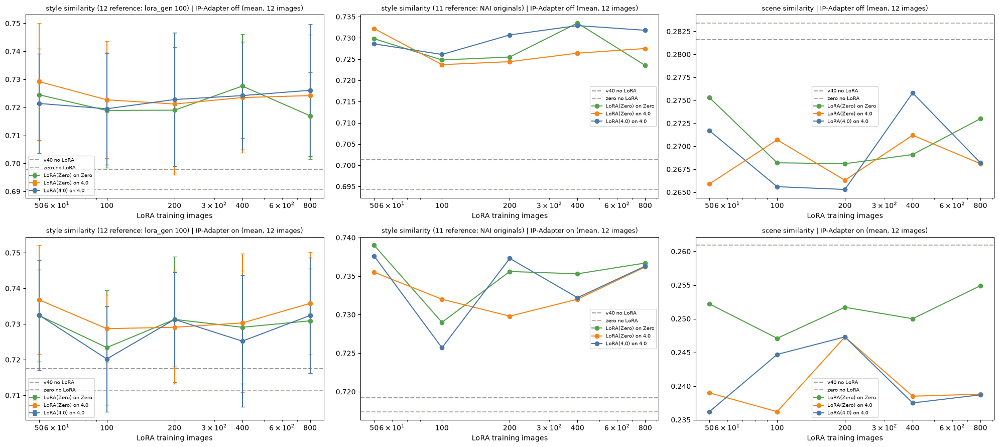

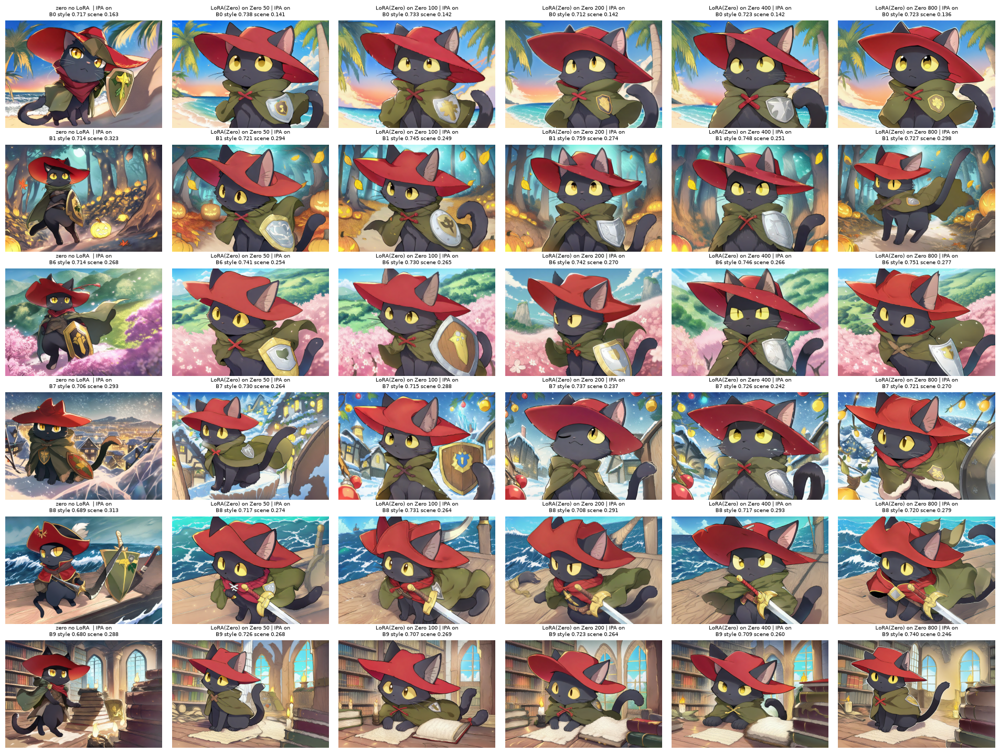

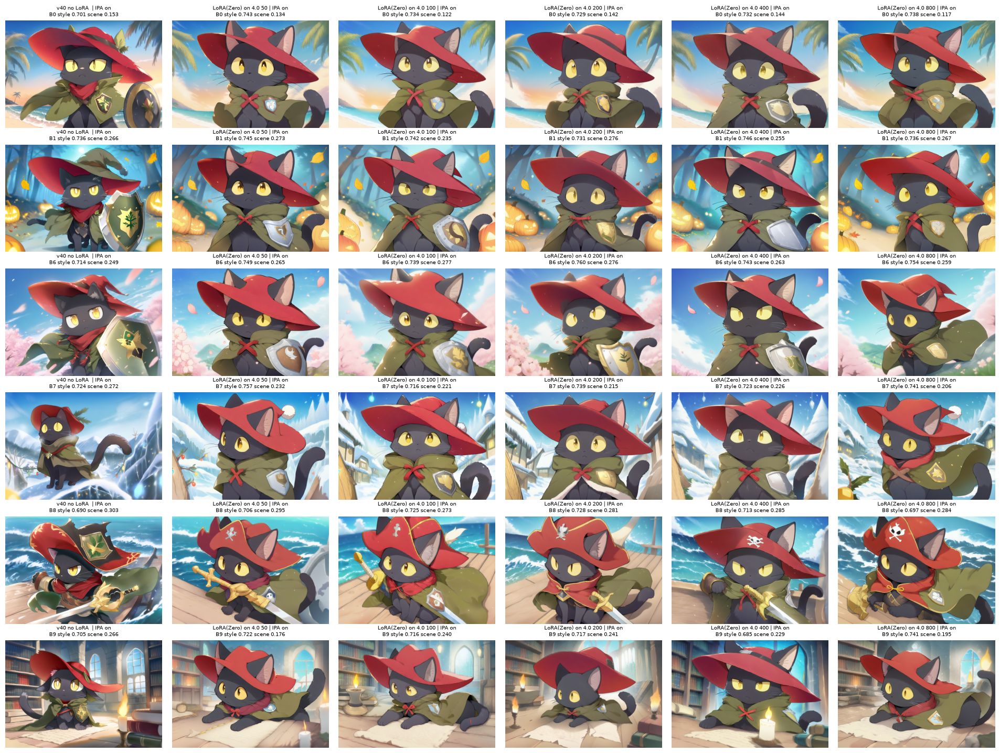

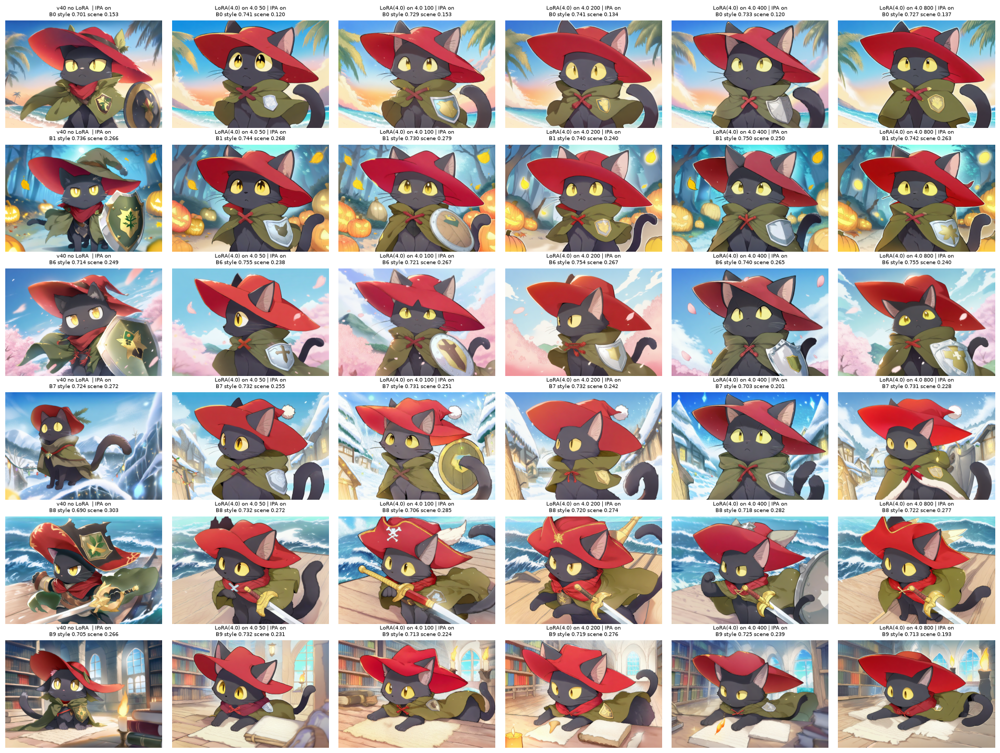

In [4]:
LABELS = ['v40 no LoRA', 'zero no LoRA'] + [APPLY_NAME[a] for a in APPLY]
COLORS = {'v40 no LoRA': '#9D9D9D', 'zero no LoRA': '#BAB0AC', 'LoRA(Zero) on Zero': '#54A24B', 'LoRA(Zero) on 4.0': '#F58518',
          'LoRA(4.0) on 4.0': '#4C78A8'}
sm = summary.reset_index()
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for row, ipa in enumerate([False, True]):
    for ax, col, title in zip(axes[row], ['style_sim', 'style_sim_orig', 'scene_sim'],
                              ['style similarity (12 reference: lora_gen 100)', 'style similarity (11 reference: NAI originals)',
                               'scene similarity']):
        for lab in LABELS:
            s = sm[(sm.label == lab) & (sm.use_ipa == ipa)].sort_values('size')
            if not len(s):
                continue
            if s['size'].max() == 0:
                ax.axhline(s[col].iloc[0], color=COLORS[lab], linestyle='--', label=lab)
            else:
                ax.errorbar(s['size'], s[col], yerr=s['style_std'] if col == 'style_sim' else None, marker='o', capsize=3,
                            color=COLORS[lab], label=lab)
        ax.set_xscale('log')
        ax.set_xticks(SIZES, [str(x) for x in SIZES])
        ax.set_xlabel('LoRA training images')
        ax.set_title(f"{title} | IP-Adapter {'on' if ipa else 'off'} (mean, 12 images)", fontsize=9)
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT_DIR / 'cl_scores.png', dpi=80)
plt.show()

# 적용 조합마다 그림 (seed 0): 행 = 장면, 열 = LoRA 없음(같은 기준 모델) + 장수별, IP-Adapter 켬
for a, t in APPLY:
    lab = APPLY_NAME[(a, t)]
    cols = [(f'{a} no LoRA', 0)] + [(lab, s) for s in SIZES]
    fig, axes = plt.subplots(len(SCENES), len(cols), figsize=(3.2 * len(cols), 2.4 * len(SCENES)), squeeze=False)
    for i, s in enumerate(SCENES.itertuples()):
        for j, (l, size) in enumerate(cols):
            r = cs[(cs.label == l) & (cs['size'] == size) & (cs['item'] == s.item) & (cs.seed == 0) & cs.use_ipa]
            ax = axes[i, j]
            ax.axis('off')
            if len(r):
                r = r.iloc[0]
                ax.imshow(Image.open(OUT_DIR / r.file))
                ax.set_title(f'{l} {size or ""} | IPA on\n{s.item} style {r.style_sim:.3f} scene {r.scene_sim:.3f}', fontsize=7)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"cl_grid_{a}_{t}.png", dpi=45)
    plt.show()